# D01 · A faster student can learn the wrong boundary
Learn to separate format compliance, task accuracy and generalization. Compare a classical router, teacher, prompted student and distilled student; then reason about a quality gate before amortizing training.
**Prerequisites:** basic Python and the [learning guide](../docs/LEARNING_GUIDE.md).
**Evidence boundary:** the charts read the recorded October 26, 2026 experiments by default. Running this notebook recomputes plots and teaching calculations; it does not retrain a model or run new model inference. Illustrative examples below are labeled separately. The [notebook guide](README.md) explains setup, provenance, and how to export your own completed runs.

## Load the evidence
Run all cells in order. The loader prints the run IDs, dates, seeds and scope. A custom export does not automatically rewrite the historical interpretation in this lesson.

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt

# Works when Jupyter starts in the repository root or notebooks/.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/lab.py").is_file() and (p / "src/ml_training").is_dir())
for folder in [ROOT / "notebooks", ROOT / "src"]:
    if str(folder) not in sys.path:
        sys.path.insert(0, str(folder))
from lab import load_demo, style, grouped_bars
style()

# None uses the compact checked-in snapshot. To inspect a new export, set an
# explicit path, e.g. ROOT / "artifacts/my-notebook-results.json". Missing files fail.
SNAPSHOT_PATH = None
d = load_demo("D01", SNAPSHOT_PATH)

D01 | recorded experiment data | recorded_results.json
Recorded local educational experiments. Inspect run dates, seeds and source manifests before comparing results. No production or physical-device validation.
Run: artifacts/distillation/local-s41-20261026T171916Z-abf0ce | recorded: 20261026T171916Z | seed: 41


## The concept
Distillation here means supervised learning from checked teacher answers. It does not match teacher logits. The student learns a mapping from request text to a strict intent/account JSON object.
Joint accuracy requires both routing and extraction to be correct. Generated test tickets and independently written challenges come from different distributions; plot them separately. A perfect score on one distribution does not imply coverage of ambiguity or negation.

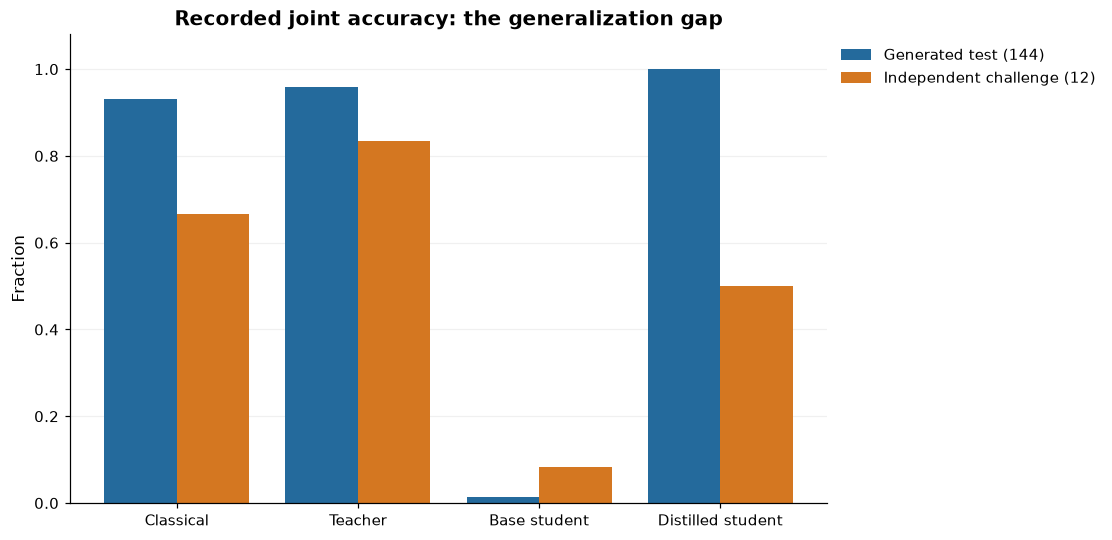

In [2]:
variants = ['classical', 'teacher', 'base_student', 'tuned_student']
labels = ['Classical', 'Teacher', 'Base student', 'Distilled student']
grouped_bars(labels, {
    'Generated test (144)': [d['metrics'][v]['joint_accuracy'] for v in variants],
    'Independent challenge (12)': [d['challenge'][v]['joint_accuracy'] for v in variants],
}, title='Recorded joint accuracy: the generalization gap')
plt.show()

In [3]:
c = d.get('curation')
if c is None:
    print('This snapshot has no curation record.')
else:
    print(f"Teacher answers kept: {c['accepted']}/{c['examples']}; every kept answer equals the oracle label: {c['accepted_equal_oracle']}")
    print('Examples removed, by training template:', c['rejected_by_template'])
    print(f"Generated-test joint accuracy | teacher: {d['metrics']['teacher']['joint_accuracy']:.4f}"
          f" | distilled student: {d['metrics']['tuned_student']['joint_accuracy']:.4f}")

Teacher answers kept: 1974/2016; every kept answer equals the oracle label: True
Examples removed, by training template: {'train-query-2': 42}
Generated-test joint accuracy | teacher: 0.9583 | distilled student: 1.0000


**What the teacher contributed.** A teacher answer is kept only when it exactly matches the synthetic oracle label, so every training target is a gold label. The teacher decides which examples are used, not what they say. All 42 removed examples came from one ambiguous training template, “List the closed billing cases.”, which the teacher routed to billing instead of query.

That is why the student can beat its teacher on generated tests. The teacher's six test errors are all the same billing-versus-query wording. Without an oracle, a real distillation pipeline would train on the teacher's answers and the student would inherit that confusion. Ask what checks your own teacher labels before crediting the student with the teacher's quality.

### Inspect the costly slice
Escalation recall is the fraction of requests that should be escalated that were correctly escalated. It is not the overall escalation rate. A router that always chooses a supported intent may appear decisive while failing the requests it should hand back.

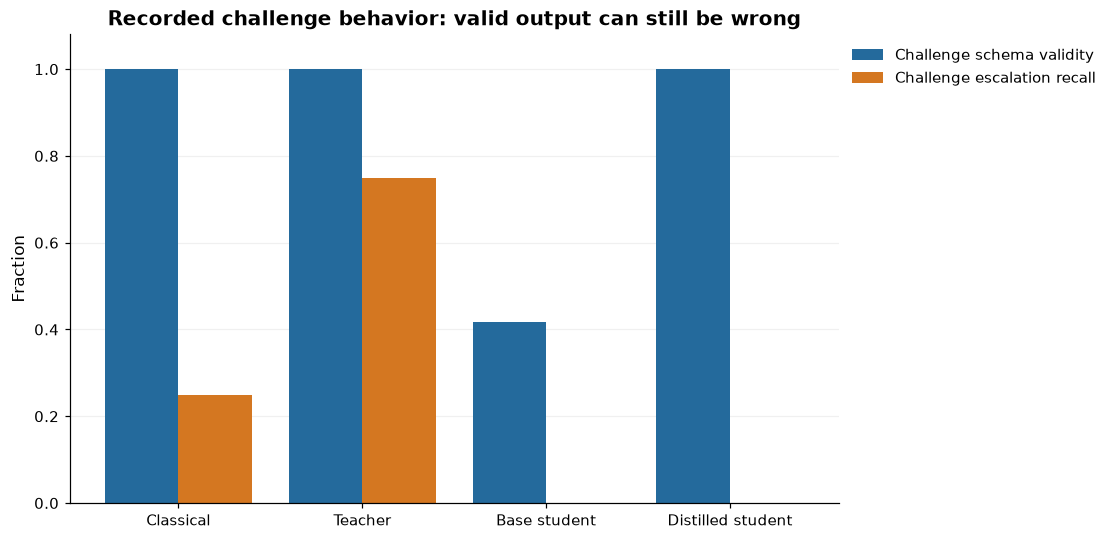

In [4]:
grouped_bars(labels, {
    'Challenge schema validity': [d['challenge'][v]['schema_validity'] for v in variants],
    'Challenge escalation recall': [d['challenge'][v]['escalation_recall'] for v in variants],
}, title='Recorded challenge behavior: valid output can still be wrong')
plt.show()

### Change an assumption: is the training work amortized?
The following is a **time-only illustration**, not a cost estimate. The historical ratio divides labeling plus training time by batch-1 p95 savings. Those quantities have different measurement conditions, so this is not a throughput forecast. Energy, hardware cost, maintenance and quality loss are absent. Before moving the slider in your head, decide whether the student passes your quality requirement.

If the run records no positive finite break-even, the cell reports that limitation and draws no savings forecast. A missing break-even is a valid negative result.

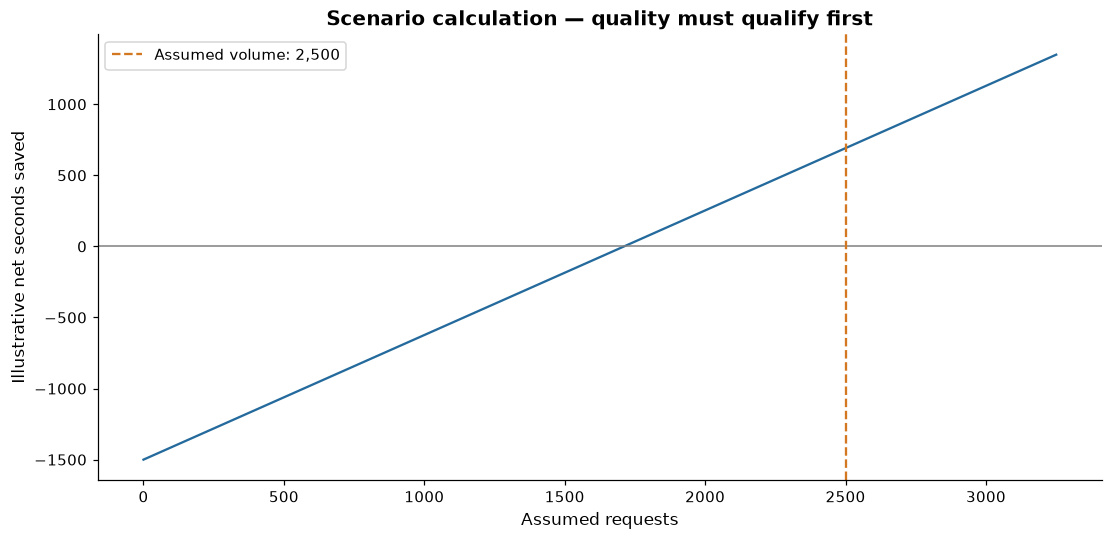

In [5]:
request_volume = 2500  # Try 500 or 10000; illustrative future workload.
costs = d['costs']
fixed_seconds = costs['teacher_labeling_seconds'] + costs['student_training_and_validation_seconds']
break_even = costs['time_only_break_even_requests']
if break_even is None or not np.isfinite(break_even) or break_even <= 0:
    print('No positive time-only break-even was recorded; no savings forecast is drawn.')
else:
    saved_seconds_per_request = fixed_seconds / break_even
    volume = np.linspace(0, max(request_volume * 1.3, 3000), 100)
    fig, ax = plt.subplots(layout='constrained')
    ax.plot(volume, volume * saved_seconds_per_request - fixed_seconds)
    ax.axhline(0, color='gray', lw=1)
    ax.axvline(request_volume, color='#d47721', ls='--', label=f'Assumed volume: {request_volume:,}')
    ax.set(xlabel='Assumed requests', ylabel='Illustrative net seconds saved',
           title='Scenario calculation — quality must qualify first')
    ax.legend(); plt.show()

**Interpretation check:** why does the distilled student's 100% generated-test score not justify replacing the teacher? The challenge result is 6/12 and escalation recall is zero. The sample is small, so neither its successes nor failures define all future behavior. Collect representative ambiguity cases before making the economic decision.

## What you learned and when to use it
Distillation can reduce repeated inference work for a stable, well-covered task. A classical or encoder classifier may provide a simpler interface. Here the independent challenge reveals a quality problem that a break-even chart cannot cancel.
**Architecture exercise:** state a quality floor, a simpler alternative, and the evidence that would make you reject this approach. Compare your answer with the [decision guide](../docs/ARCHITECTURE_DECISION_GUIDE.md#d01--distill-a-repeated-language-task).
**Train or run the actual model:** follow the [D01 tutorial](../docs/SLM_DEMOS.md#d01-distillation). Training stays in its existing locked environment; this notebook stays light enough to run without model downloads.
[All visual lessons](README.md) · [Production tradeoffs](../docs/PRODUCTION_TRADEOFFS.md)